# TRABAJO PRACTICO INTEGRADOR - SEGUNDO PARCIAL
#### INTEGRANTES:
- Bianciotto Sofia - 1241171
- Cebreiros Juana - 1238673
- Lacava Giuliana - 1239334
- Lazaro Martina - 1238503
##### TEMA: Utilizaremos un dataset de una veterinaria, con el objetivo de predecir si un animal está sano o enfermo, y si lo está, si padece de otitis o presenta un cuadro dermatológico.

### PARTE 1 - CARGA DE DATOS

In [ ]:
#Importamos librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

In [ ]:
df = pd.read_csv("Vet_Clinical_Dataset.csv")
print("El Dataset fue cargado exitosamente. Tiene las siguientes dimensiones:")
df.shape

El Dataset fue cargado exitosamente. Tiene las siguientes dimensiones:


(2000, 15)

In [ ]:
# Creamos una columna para distinguir si el paciente está sano o enfermo
df['estado_salud'] = df['definitive diagnosis'].apply(lambda x: 'sano' if x == 'healthy' else 'enfermo')

### PARTE 2 - EDA INICIAL - PREPARACIÓN Y LIMPIEZA DE DATOS

En los siguientes cuadros de codigo, revisaremos el dataset y los datos del mismo, verificando si hay valores nulos, duplicados, faltantes. Luego analizaremos que hacer frente a cada problema encontrado. 

In [ ]:
df.columns

Index(['Patient ID', 'ownership_status', 'intake date', 'booking date',
       'species', 'breed', 'age', 'sex', 'weight', 'temperature', 'heart rate',
       'intake location', 'Body condition score', 'wood lamp fungal',
       'definitive diagnosis', 'estado_salud'],
      dtype='str')

Que informacion nos da cada columna:
- Patitient ID: codigo de identificacion unico para cada caso. 
- ownership_status: origen del animal (owned - recued - lost_rescued)
- intake date: fecha en que el animal fue llevado a la consulta para la evaluacion clinica
- booking date: fecha de una consulta con reserva previa
- intake location: area geografica (en la ciudad de Makati)
- species: tipo de animal
- breed: clasificacion de raza
- age: edad del paciente
- sex: genero del paciente
- weight: peso del paciente (en kg)
- temperature: temperatura corporal al ingreso a la consulta (en grados Celsius)
- heart rate: latidos por minuto
- body condition score: condicion corporal en una escala del 1 (escualido) al 9 (obesidad)
- wood lamp fungal: test para detectar infecciones (positive - negative)
- definitive diagnosis: el diagnostico final dictado por el veterinario de turno

In [ ]:
df.head(3) #Los primeros 3 registros del dataset


,ownership_status,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis,estado_salud,categoria_diagnostico
0,rescued,canine,Aspin,4.000000,male,6.7,39.1,114.0,"East Rembo, Makati City",4.0,Negative,Bacterial Dermatitis and Bacterial Otitis,enfermo,Piel y Ótico (Mixto)
1,owned,canine,Shih Tzu,9.000000,male,9.7,39.1,102.0,Desconocido,4.0,Negative,Atopic Dermatitis,enfermo,Afección de Piel
2,owned,canine,Golden Retriever,0.230769,male,11.7,39.1,102.0,Desconocido,3.0,Negative,Bacterial Dermatitis and Bacterial Otitis,enfermo,Piel y Ótico (Mixto)


In [ ]:
df.tail(3) #Los últimos 3 registros del dataset

,ownership_status,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis,estado_salud,categoria_diagnostico
1997,rescued,canine,Aspin,0.211538,male,4.0,39.2,102.0,"Urdaneta, Makati City",4.0,Positive,Ringworm,enfermo,Afección de Piel
1998,rescued,feline,Puspin,10.000000,female,5.0,38.1,196.0,"San Lorenzo, Makati City",7.0,Negative,Bacterial Dermatitis and Bacterial Otitis,enfermo,Piel y Ótico (Mixto)
1999,rescued,feline,Siamese,0.230769,female,2.0,38.3,172.0,"Bel-Air, Makati City",7.0,Negative,Ear Mites and Yeast Otitis,enfermo,Afección Ótica


In [ ]:
df.sample(5) #5 registros aleatorios del datset

,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis,estado_salud
581,25077815,owned,NaN,7/10/2025,feline,Persian,10 weeks,male,1.8,38.4,111.0,NaN,3.0,Negative,healthy,sano
1875,23095237,rescued,9/16/2023,NaN,canine,Aspin,10 months,female,3.1,38.6,112.0,"East Rembo, Makati City",7.0,Negative,Yeast Otitis,enfermo
1329,24029609,owned,NaN,2/20/2024,feline,Puspin,8 months,female,4.6,39.0,203.0,NaN,5.0,Negative,Ear Mites,enfermo
461,23012042,rescued,2023-01-05,NaN,canine,Aspin,11 weeks,male,5.4,39.1,110.0,"Pembo, Makati City",3.0,Negative,Bacterial Dermatitis,enfermo
30,25085575,lost_rescued,2025-08-06,NaN,canine,Shih Tzu,10 months,male,8.6,38.4,NaN,"South Cembo, Makati City",4.0,Negative,Yeast Dermatitis and Yeast Otitis,enfermo


In [ ]:
df.info() #Panorama general del dataset. Cantidad de filas, columnas, nombres de las columnas, cantidad de valores no nulos por columna y tipo de dato de cada columna.

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Patient ID            2000 non-null   int64  
 1   ownership_status      2000 non-null   str    
 2   intake date           866 non-null    str    
 3   booking date          1134 non-null   str    
 4   species               2000 non-null   str    
 5   breed                 2000 non-null   str    
 6   age                   2000 non-null   str    
 7   sex                   2000 non-null   str    
 8   weight                2000 non-null   float64
 9   temperature           2000 non-null   float64
 10  heart rate            1689 non-null   float64
 11  intake location       866 non-null    str    
 12  Body condition score  1942 non-null   float64
 13  wood lamp fungal      2000 non-null   str    
 14  definitive diagnosis  2000 non-null   str    
 15  estado_salud          2000 non-n

Podemos observar que el dataset contiene 2000 filas y 15 columnas, de las cuales 10 no tienen ningun valor nulo. "intake date" - "booking date" - "heart rate" - "intake location" - "body condition score" tienen valores nulos. 

In [ ]:
df.describe() #Resumen estadístico de las variables numericas

,Patient ID,weight,temperature,heart rate,Body condition score
count,2.000000e+03,2000.000000,2000.000000,1689.000000,1942.000000
mean,2.404418e+07,7.652150,38.711250,129.512729,4.845520
std,8.212429e+05,7.340566,0.294859,41.831217,1.453319
min,2.301009e+07,0.700000,38.000000,66.000000,3.000000
25%,2.309690e+07,3.100000,38.500000,96.000000,3.000000
50%,2.406290e+07,4.500000,38.700000,115.000000,5.000000
75%,2.503390e+07,9.700000,39.000000,165.000000,6.000000
max,2.512987e+07,35.800000,39.300000,230.000000,7.000000


- count: cantidad de valores no nulos
- mean: promedio
- std: desvio estandar
- min: valor minimo 
- 25% - 75%: primer y tercer cuartil
- 50%: mediana
- max: valor maximo

observaciones:
- "heart rate" y "body condition score" tiene valores nulos 
- este no es un analisis significativo para la variable Patient ID, ya que es una variable unica de cada paciente. Serviría mas analizarla como "object". (ver de hacer una transformacion a object)
- en "weight" y "heart rate" el promedio se encuentra alejado del valor de la media, tienen un desvio estandar elevado, por lo que los datos estan dispersos. Puede significar la presencia de algun outlier.

In [ ]:
df.describe(include="object") #Ahora aplicado a las variables categoricas 

C:\Users\lacav\AppData\Local\Temp\ipykernel_22020\2158270276.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object") #Ahora aplicado a las variables categoricas


,ownership_status,species,breed,sex,intake location,wood lamp fungal,definitive diagnosis,estado_salud,categoria_diagnostico
count,2000,2000,2000,2000,2000,2000,2000,2000,2000
unique,3,2,13,2,17,2,13,2,4
top,owned,canine,Aspin,female,Desconocido,Negative,Ear Mites and Yeast Otitis,enfermo,Afección Ótica
freq,1134,1199,484,1008,1134,1683,181,1884,644


- count: valores no nulos
- unique: cantidad de valores unicos
- top: valor mas frecuete
- freq: frecuencia del valor mas frecuente

observaciones: 
- sobre "ownership status":     
        - el valor mas repetido es "owned" apareciendo 1134 veces de 2000 registros totales, lo que significa que al menos de la mitad de los animmales atendidos tenían dueño. 
- sobre "intake date":
       - hay varios valores faltantes, de 2000 ingresos, solo se registraron 866 en esta categoría. Las fechas de ingreso estan muy distribuidas, no existe una en particular que acumule un gran porcentaje de animales ingresados. 
- sobre "booking date":
        - lo mismo que para la variable anterior, presenta muchos datos faltantes 
- sobre "species":
        - hay solamente 2 tipos de especies, siendo apenas más de la mitad "canine"
- sobre "breed":
        - hay 13 razas diferentes, siendo "Aspin" la más frecuente, representando el 24,2% de los registros
- sobre "age":
        - de 26 edades registradas, ninguna representa una gran mayoria de los datos. 
- sobre "sex":
        - el sexo femenino esta muy levemente más repetido que el sexo masculino (los dos unicos valores posibles)
- sobre "intake location":
        - ninguna de las 16 ubicaciones esta mucho más repetida que el resto. Hay que considerar que hay más de la mitad de valores faltantes
- sobre "wood lamp fungal":
        - la mayoria de los resultados dio negativo (el 84,15%). Solo el 15,85% dio positivo. Todos los animales fueron sometidos al test.
- sobre "definitive diagnosis":
        - hubo 13 diagnosticos distintos, el mas repetido "ear mites and yeast otitis", sin predominar ampliamente por sobre el resto

In [ ]:
df.describe(include="all") #Esta es la forma de incluir lo de ambas tablas anteriores en una sola

,ownership_status,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis,estado_salud,categoria_diagnostico
count,2000,2000,2000,2000.000000,2000,2000.000000,2000.000000,2000.000000,2000,2000.000000,2000,2000,2000,2000
unique,3,2,13,NaN,2,NaN,NaN,NaN,17,NaN,2,13,2,4
top,owned,canine,Aspin,NaN,female,NaN,NaN,NaN,Desconocido,NaN,Negative,Ear Mites and Yeast Otitis,enfermo,Afección Ótica
freq,1134,1199,484,NaN,1008,NaN,NaN,NaN,1134,NaN,1683,181,1884,644
mean,NaN,NaN,NaN,2.729029,NaN,7.652150,38.711250,129.189500,NaN,4.850000,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,3.436170,NaN,7.340566,0.294859,40.675876,NaN,1.432315,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,0.153846,NaN,0.700000,38.000000,66.000000,NaN,3.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,0.416667,NaN,3.100000,38.500000,100.000000,NaN,3.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,0.833333,NaN,4.500000,38.700000,114.000000,NaN,5.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,5.000000,NaN,9.700000,39.000000,168.000000,NaN,6.000000,NaN,NaN,NaN,NaN


Tranformaremos la variable "age" a numerica para poder trabajar mejor con ella. La edad es un dato numerico actualmente expresado como texto, para poder hacer operaciones, comparaciones e incluso el análisis estadístico, es necesario que pertezca a la categoria de variables numericas. 

In [ ]:
df["age"].unique() #Observamos los posibles valores y el tipo (str). La tranformaremos a una variable numerica

<StringArray>
[  '4 years',   '9 years',  '12 weeks',  '12 years',   '3 years',   '6 years',
  '10 years',  '9 months',   '5 years', '11 months',   '1 years',  '5 months',
  '8 months',  '7 months',   '8 weeks',   '7 years',  '11 years',   '9 weeks',
   '2 years',  '6 months', '10 months',  '4 months',   '8 years',  '3 months',
  '11 weeks',  '10 weeks']
Length: 26, dtype: str

In [ ]:
#Creamos una función de apoyo para la transformación
def convertir_age(edad):
    edad = str(edad).lower().strip()
    if "years" in edad:
        return float(edad.replace("years" , "").strip())
    elif "months" in edad:
        return float(edad.replace("months" , "").strip()) / 12
    elif "weeks" in edad:
        return float(edad.replace("weeks" , "").strip()) / 52
    else:
        return "edad no valida"

Aclaración: ahora las edades estaran todas expresadas en funcion de años, es decir, 6 meses sera 0.5 (años), 11 semanas sera 0.2115538... (años).

In [ ]:
df["age"] = df["age"].apply(convertir_age)
df["age"]

0       edad no valida
1       edad no valida
2       edad no valida
3       edad no valida
4       edad no valida
             ...      
1995    edad no valida
1996    edad no valida
1997    edad no valida
1998    edad no valida
1999    edad no valida
Name: age, Length: 2000, dtype: str

In [ ]:
df["age"].dtype

dtype('float64')

In [ ]:
df.describe() #Ahora podemos incluir la variable "age" en el analisis de las numericas

,weight,temperature,heart rate,Body condition score
count,2000.000000,2000.000000,2000.000000,2000.000000
mean,7.652150,38.711250,129.189500,4.850000
std,7.340566,0.294859,40.675876,1.432315
min,0.700000,38.000000,66.000000,3.000000
25%,3.100000,38.500000,100.000000,3.000000
50%,4.500000,38.700000,114.000000,5.000000
75%,9.700000,39.000000,168.000000,6.000000
max,35.800000,39.300000,230.000000,7.000000


In [ ]:
df["ownership_status"].value_counts() #Cuantas animales tienen dueño, fueron rescatados o estaban perdidos y fueron rescatados

ownership_status
owned           1134
rescued          684
lost_rescued     182
Name: count, dtype: int64

De 2000 animales: 56,7% tenían dueño - 32,4% fueron rescatados - 9,1% eran perdidos y fueron rescatados

In [ ]:
df["breed"].value_counts() #Cuantos ingresos hay de cada raza

breed
Aspin                 484
Puspin                342
Persian               121
Domestic Shorthair    120
Siberian Husky        113
Chihuahua             110
British Shorthair     109
Siamese               109
French Bulldog        109
Shih Tzu              102
Golden Retriever       98
Pomeranian             93
Poodle                 90
Name: count, dtype: int64

In [ ]:
df["intake location"].value_counts() #Cuantos ingresos hay por cada ubicación

intake location
South Cembo, Makati City            69
Palanan, Makati City                64
Pitogo, Makati City                 64
Urdaneta, Makati City               62
Bel-Air, Makati City                56
Guadalupe Nuevo, Makati City        56
East Rembo, Makati City             55
Pembo, Makati City                  54
San Lorenzo, Makati City            53
Guadalupe Viejo, Makati City        53
Makati Central Business District    51
Rizal, Makati City                  49
West Rembo, Makati City             47
Comembo, Makati City                46
Poblacion, Makati City              46
San Antonio, Makati City            41
Name: count, dtype: int64

In [ ]:
df.duplicated().sum()

np.int64(0)

No hay ningun registro con exactamente los mismos valores en todas sus columnas.

In [ ]:
df.isnull().sum() #Muestra los valores nulos por columna

ownership_status         0
species                  0
breed                    0
age                      0
sex                      0
weight                   0
temperature              0
heart rate               0
intake location          0
Body condition score     0
wood lamp fungal         0
definitive diagnosis     0
estado_salud             0
categoria_diagnostico    0
dtype: int64

Podemos observar:
- "intake date" tiene 1134 valores nulos.
- "booking date" tiene 866 valores nulos.
- "heart rate" tiene 311 valores nulos.
- "intake location" tiene 1134 valores nulos. 
- "body condition score" tiene 58 valores nulos.
-  El resto de las columnas no presentan valores nulos. 

In [ ]:
nulos_porcentaje = df.isnull().sum() / (len(df)) * 100

print(nulos_porcentaje) #Muestra el porcentaje de datos nulos por columna

Patient ID               0.00
ownership_status         0.00
intake date             56.70
booking date            43.30
species                  0.00
breed                    0.00
age                      0.00
sex                      0.00
weight                   0.00
temperature              0.00
heart rate              15.55
intake location         56.70
Body condition score     2.90
wood lamp fungal         0.00
definitive diagnosis     0.00
estado_salud             0.00
dtype: float64


In [ ]:
df[df.isnull().any(axis=1)] #Visualización de registros con al menos 1 dato faltante

,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis,estado_salud
0,25021825,rescued,2/28/2025,NaN,canine,Aspin,4.000000,male,6.7,39.1,114.0,"East Rembo, Makati City",4.0,Negative,Bacterial Dermatitis and Bacterial Otitis,enfermo
1,23110410,owned,NaN,11/13/2023,canine,Shih Tzu,9.000000,male,9.7,39.1,NaN,NaN,4.0,Negative,Atopic Dermatitis,enfermo
2,23124507,owned,NaN,12/2/2023,canine,Golden Retriever,0.230769,male,11.7,39.1,NaN,NaN,3.0,Negative,Bacterial Dermatitis and Bacterial Otitis,enfermo
3,23014013,owned,NaN,2023-01-07,feline,Puspin,12.000000,female,4.1,38.7,NaN,NaN,3.0,Negative,Ear Mites and Yeast Otitis,enfermo
4,24073658,rescued,7/17/2024,NaN,canine,Aspin,3.000000,female,8.1,39.0,79.0,"Comembo, Makati City",3.0,Negative,Ear Mites,enfermo
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,25097643,owned,NaN,2025-09-02,canine,Aspin,0.750000,female,13.3,39.0,104.0,NaN,7.0,Negative,Bacterial Dermatitis,enfermo
1996,23052008,rescued,5/20/2023,NaN,canine,French Bulldog,7.000000,female,22.0,38.9,NaN,Makati Central Business District,5.0,Negative,Atopic Dermatitis,enfermo
1997,24124383,rescued,12/18/2024,NaN,canine,Aspin,0.211538,male,4.0,39.2,NaN,"Urdaneta, Makati City",4.0,Positive,Ringworm,enfermo
1998,24127367,rescued,12/19/2024,NaN,feline,Puspin,10.000000,female,5.0,38.1,196.0,"San Lorenzo, Makati City",7.0,Negative,Bacterial Dermatitis and Bacterial Otitis,enfermo


Eliminaremos las columnas "Patient ID", "intake date" y "booking date" ya que no son relevantes para el analisis que relizaremos, y además las últimas dos, poseen una gran volumen de nulos, por lo que seria muy dificil hacer una imputacion acertada.

In [ ]:
df = df.drop(columns=["Patient ID" , "intake date" , "booking date"])

In [ ]:
df.columns #Confirmamos que hayan sido eliminadas

Index(['ownership_status', 'species', 'breed', 'age', 'sex', 'weight',
       'temperature', 'heart rate', 'intake location', 'Body condition score',
       'wood lamp fungal', 'definitive diagnosis', 'estado_salud'],
      dtype='str')

### Imputacion de nulos

Para la variable "heart rate", separaremos la imputacion segun felinos y caninos, ya que segun la especie, varian mucho los valores. Completarlos con una media general, puede terminar en un valor poco representativo para amabas especies. 

In [ ]:
df.groupby("species")["heart rate"].median()

species
canine    102.0
feline    172.0
Name: heart rate, dtype: float64

In [ ]:
df["heart rate"] = df.groupby("species")["heart rate"].transform(
    lambda x: x.fillna(x.median())
)

In [ ]:
df["Body condition score"] = df["Body condition score"].fillna(df["Body condition score"].median())

In [ ]:
df["intake location"] = df["intake location"].fillna("Desconocido")

In [ ]:
df.head(15) #Observamos el dataset sin nulos

,ownership_status,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis,estado_salud,categoria_diagnostico
0,rescued,canine,Aspin,edad no valida,male,6.7,39.1,114.0,"East Rembo, Makati City",4.0,Negative,Bacterial Dermatitis and Bacterial Otitis,enfermo,Piel y Ótico (Mixto)
1,owned,canine,Shih Tzu,edad no valida,male,9.7,39.1,102.0,Desconocido,4.0,Negative,Atopic Dermatitis,enfermo,Afección de Piel
2,owned,canine,Golden Retriever,edad no valida,male,11.7,39.1,102.0,Desconocido,3.0,Negative,Bacterial Dermatitis and Bacterial Otitis,enfermo,Piel y Ótico (Mixto)
3,owned,feline,Puspin,edad no valida,female,4.1,38.7,172.0,Desconocido,3.0,Negative,Ear Mites and Yeast Otitis,enfermo,Afección Ótica
4,rescued,canine,Aspin,edad no valida,female,8.1,39.0,79.0,"Comembo, Makati City",3.0,Negative,Ear Mites,enfermo,Afección Ótica
5,owned,canine,Aspin,edad no valida,male,10.3,39.2,102.0,Desconocido,4.0,Negative,Yeast Dermatitis,enfermo,Afección de Piel
6,owned,feline,British Shorthair,edad no valida,female,5.6,38.9,172.0,Desconocido,5.0,Negative,Yeast Otitis,enfermo,Afección Ótica
7,lost_rescued,canine,Chihuahua,edad no valida,male,2.7,38.7,126.0,"Urdaneta, Makati City",5.0,Negative,Ear Mites and Yeast Otitis,enfermo,Afección Ótica
8,rescued,feline,Puspin,edad no valida,male,4.9,38.2,192.0,"Rizal, Makati City",4.0,Negative,Ear Mites and Yeast Otitis,enfermo,Afección Ótica
9,owned,canine,Poodle,edad no valida,female,5.7,39.0,102.0,Desconocido,6.0,Negative,Bacterial Otitis,enfermo,Afección Ótica


In [ ]:
df.isnull().sum()

ownership_status         0
species                  0
breed                    0
age                      0
sex                      0
weight                   0
temperature              0
heart rate               0
intake location          0
Body condition score     0
wood lamp fungal         0
definitive diagnosis     0
estado_salud             0
categoria_diagnostico    0
dtype: int64

#### BUSQUEDA DE OUTLIERS

Para buscar valores imposibles, debedos determinar que cosas significarian que el dato no sea validos:
- Animales con edades negativas, o muy grandes. La esperanza de vida entre ambas especies es muy similar, por lo que tomaremos a los mayores de 35 años, como una edad imposible. 
- Animales con peso nulo, o negativo. 
- Temperaturas corporales negativas, muy bajas o muy elevadas
- Frecuencias cardiacas negativas
- Puntaje de condicion corporal fuera de la escala utilizada

In [ ]:
# 1. EDAD

print("EDADES NEGATIVAS (VALORES IMPOSIBLES):")

display(df[df["age"] < 0])

print("EDADES MAYORES A 35 AÑOS (OUTLIERS EXTREMOS):")

display(df[df["age"] > 35])



# 2. PESO

print("PESOS IGUALES O MENORES A 0 (VALORES IMPOSIBLES):")

display(df[df["weight"] <= 0])

print("FELINOS CON PESO MAYOR A 30 KG (outlier):")

display(df[
    (df["species"] == "feline") &
    (df["weight"] > 30)
])

print("CANINOS CON PESO MAYOR A 120 KG (outlier):")

display(df[
    (df["species"] == "canine") &
    (df["weight"] > 120)
])



# 3. TEMPERATURA

print("TEMPERATURAS NEGATIVAS O IGUALES A 0 (valor imposible):")

display(df[df["temperature"] <= 0])

print("TEMPERATURAS MENORES A 30 °C (outlier):")

display(df[
    (df["temperature"] > 0) &
    (df["temperature"] < 30)
])

print("TEMPERATURAS MAYORES A 43 °C (outlier):")

display(df[df["temperature"] > 43])



# 4. FRECUENCIA CARDÍACA

print("FRECUENCIAS CARDÍACAS NEGATIVAS O IGUALES A 0 (valor imposible):")

display(df[df["heart rate"] <= 0])

print("FELINOS CON FRECUENCIA CARDÍACA EXTREMA (outlier):")

display(df[
    (df["species"] == "feline") &
    ((df["heart rate"] < 65) | (df["heart rate"] > 250))
])

print("CANINOS CON FRECUENCIA CARDÍACA EXTREMA (outlier):")

display(df[
    (df["species"] == "canine") &
    ((df["heart rate"] < 40) | (df["heart rate"] > 230))
])



# 5. BODY CONDITION SCORE

print("PUNTAJES FUERA DE LA ESCALA DE 1 A 9 (valores imposibles):")

display(df[
    (df["Body condition score"] < 1) |
    (df["Body condition score"] > 9)
])


EDADES NEGATIVAS (VALORES IMPOSIBLES):


,ownership_status,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis,estado_salud


EDADES MAYORES A 35 AÑOS (OUTLIERS EXTREMOS):


,ownership_status,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis,estado_salud


PESOS IGUALES O MENORES A 0 (VALORES IMPOSIBLES):


,ownership_status,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis,estado_salud


... (14 outputs left out)

CANINOS CON FRECUENCIA CARDÍACA EXTREMA (outlier):


,ownership_status,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis,estado_salud


PUNTAJES FUERA DE LA ESCALA DE 1 A 9 (valores imposibles):


,ownership_status,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis,estado_salud


No hay ningun valor fuera del rango normal para los valores de cada columna, es decir, no hay outliers o valores imposibles.

## Análisis Exploratorio de Datos- EDA
En esta sección se realizará un análisis exploratorio del dataset veterinario, con el objetivo de comprender la distribución de las variables, identificar posibles patrones y estudiar las relaciones que podrían resultar relevantes para predecir el estado de los pacientes.

 ### Distribucion de las variables numéricas

#### Peso, temperatura, edad y frecuencia cardiaca - Hisotogramas
Comenzamos analizando gráficamente la distribución de las principales variables numéricas del dataset: peso, temperatura corporal, frecuencia cardíaca y edad.
Para ello, utilizaremos histogramas, que permiten visualizar la frecuencia con la que se presentan los valores de cada variable, agrupándolos en intervalos.
El objetivo de este análisis es identificar los valores más frecuentes, observar la forma de las distribuciones y detectar posibles asimetrías o concentraciones de datos. 

In [ ]:
def plot_histogramas_univariado(df):
    '''
    Grafica los histogramas de peso, temperatura
    y frecuencia cardíaca de los pacientes.
    '''

    # Histogramas
    plt.figure(figsize=(16, 4))

    # Subplot Histograma peso
    plt.subplot(1, 4, 1)
    sns.histplot(data=df, x='weight', bins=15,
                 color='#d96b93', edgecolor='black')
    plt.ylabel('Frecuencia')
    plt.title('Peso')
    plt.xlabel('Peso (kg)')

    # Subplot Histograma temperatura
    plt.subplot(1, 4, 2)
    sns.histplot(data=df, x='temperature', bins=15,
                 color='#d96b93', edgecolor='black')
    plt.ylabel('Frecuencia')
    plt.title('Temperatura')
    plt.xlabel('Temperatura (C°)')

    # Subplot Histograma frecuencia cardíaca
    plt.subplot(1, 4, 3)
    sns.histplot(data=df, x='heart rate', bins=15,
                 color='#d96b93', edgecolor='black')
    plt.ylabel('Frecuencia')
    plt.title('Frecuencia cardíaca')
    plt.xlabel('Frecuencia cardíaca (lpm)')

    # Subplot Histograma edad
    plt.subplot(1, 4, 4)
    sns.histplot(data=df, x='age', bins=15,
                color='#d96b93', edgecolor='black')
    plt.ylabel('Frecuencia')
    plt.title('Edad')
    plt.xlabel('Edad (en años)')

    # Título general centrado
    plt.suptitle(
        'Distribución de las variables numéricas',
        fontsize=14,
        ha='center'
    )

    plt.tight_layout()
    plt.show()

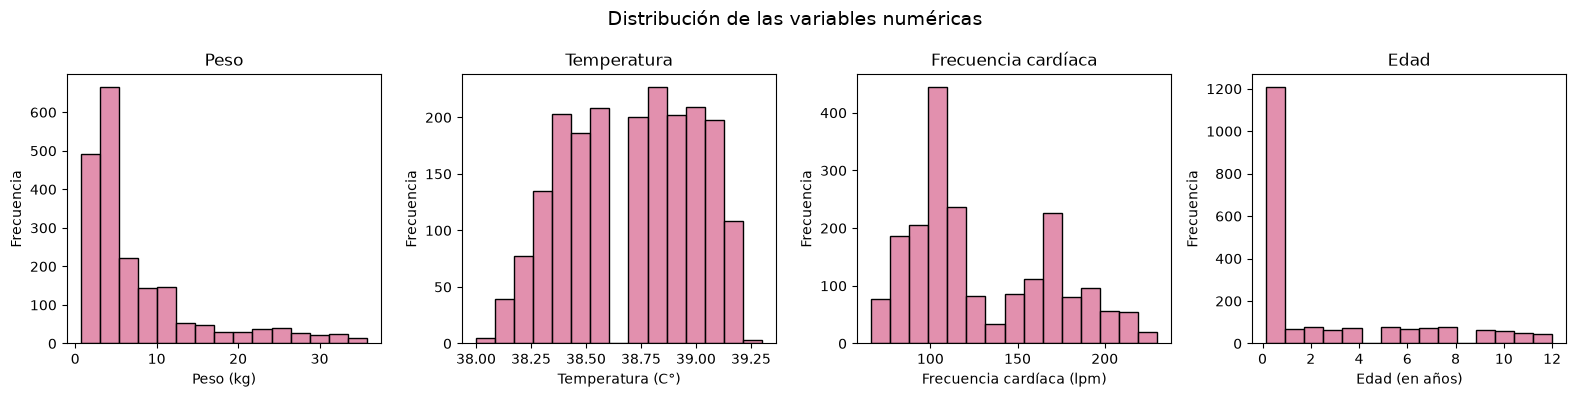

In [ ]:
plot_histogramas_univariado(df)


Interpretacion: El peso presenta una distribución asimétrica positiva, con una mayor concentración de pacientes en los valores bajos y una menor frecuencia de pesos elevados.
La temperatura corporal presenta una distribución relativamente concentrada, sin una asimetría muy marcada.
La frecuencia cardíaca muestra diferentes concentraciones de valores, que podrían estar relacionadas con las características fisiológicas de las especies presentes en el dataset.
Por último, la edad presenta una distribución fuertemente asimétrica positiva, con una concentración elevada de pacientes jóvenes y una menor frecuencia de animales de mayor edad.
Estas observaciones permiten identificar patrones que justifican profundizar el análisis mediante comparaciones entre especies y estados de salud

#### Peso, temperatura y frecuencia cardiaca- Boxplots
Para complementar el análisis realizado mediante histogramas, utilizaremos el diagrama: boxplots.
Este tipo de gráfico permite visualizar la mediana, los cuartiles, la dispersión de los datos y los posibles valores atípicos (outliers).
El objetivo es profundizar en el comportamiento de las variables e identificar posibles valores extremos que requieran un análisis adicional, considerando las diferencias entre las especies y razas presentes en el dataset.

In [ ]:
def plot_boxplots_univariado(df):
    '''
    Grafica los boxplots de peso, temperatura
    y frecuencia cardíaca de los pacientes.
    '''

    # Boxplots
    plt.figure(figsize=(16, 4))

    # Subplot Boxplot peso
    plt.subplot(1, 4, 1)
    sns.boxplot(data=df, x='weight', color='#d96b93')
    plt.xlabel('Peso (kg)')

    # Subplot Boxplot temperatura
    plt.subplot(1, 4, 2)
    sns.boxplot(data=df, x='temperature', color='#d96b93')
    plt.xlabel('Temperatura (C°)')

    # Subplot Boxplot frecuencia cardíaca
    plt.subplot(1, 4, 3)
    sns.boxplot(data=df, x='heart rate', color='#d96b93')
    plt.xlabel('Frecuencia cardíaca (lpm)')
    # Subplot Boxplot edad
    plt.subplot(1, 4, 4)
    sns.boxplot(data=df, x='age', color='#d96b93')
    plt.xlabel('Edad (en años)')

    # Título general centrado
    plt.suptitle(
        'Comparación de la distribución de tres variables numéricas',
        fontsize=14,
        ha='center'
    )

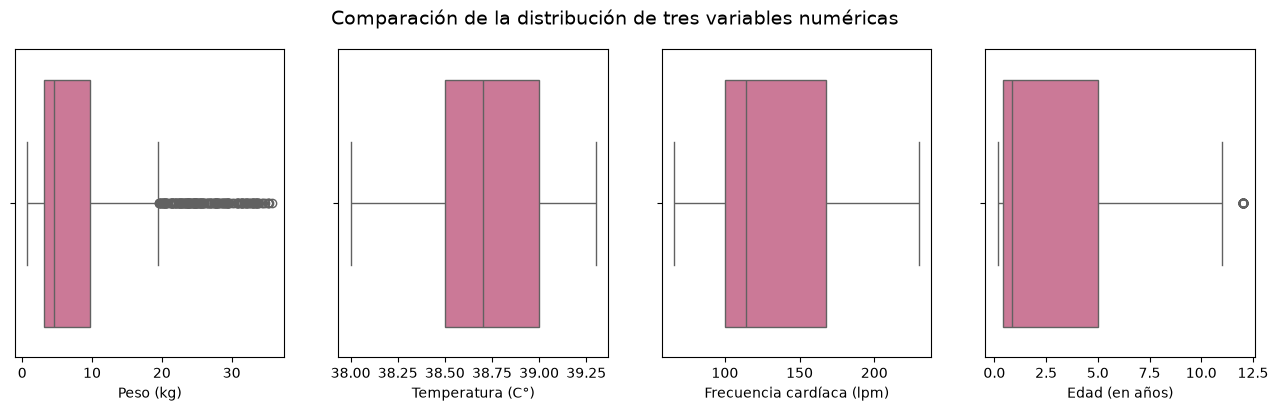

In [ ]:
plot_boxplots_univariado(df)

Interpretación: El peso presenta numerosos posibles valores atípicos en los valores elevados. Sin embargo, estos no necesariamente representan errores, ya que podrían corresponder a diferencias de tamaño entre especies y razas.
La temperatura corporal presenta una caja relativamente estrecha y no se observan valores atípicos según el criterio del boxplot.
La frecuencia cardíaca presenta una dispersión considerable dentro de su escala, sin valores atípicos visibles. Sin embargo, este gráfico no permite distinguir claramente las diferentes concentraciones observadas anteriormente en el histograma.
Finalmente, la edad presenta una mediana próxima al primer cuartil, mientras que la caja se extiende hacia edades mayores. También se observa un posible valor atípico cercano a los 12 años, que no necesariamente representa un dato incorrecto.
En conjunto, estos gráficos permiten profundizar el análisis de las distribuciones y comprender mejor la variabilidad de las características de los pacientes.

### Distribucion de la condición corporal
La variable Body condition score representa la puntuación de la condición corporal de los pacientes veterinarios.
A diferencia de las variables analizadas anteriormente, se trata de una variable numérica discreta. Por este motivo, se utilizará un gráfico de barras para visualizar la frecuencia de cada puntuación registrada.

In [ ]:
def graficar_barras(df, columna, titulo, hue=None, paso_y=None, paleta=None):
    '''
    Grafica la frecuencia de una variable mediante barras.
    Permite comparar grupos y modificar los intervalos del eje Y.
    '''

    plt.figure(figsize=(8, 4))

    if hue is None:
        sns.countplot(data=df, x=columna,
                      color='#d96b93', edgecolor='black')
    else:
        sns.countplot(data=df, x=columna, hue=hue,
                      palette=paleta, edgecolor='black')

    plt.title(titulo)
    plt.xlabel(columna)
    plt.ylabel('Cantidad de pacientes')

    if paso_y is not None:
        limite_y = int(plt.ylim()[1])
        plt.yticks(range(0, limite_y + paso_y, paso_y))

    if hue is not None:
        plt.legend(title='Estado de salud' if hue == 'estado_salud' else hue)

    plt.show()



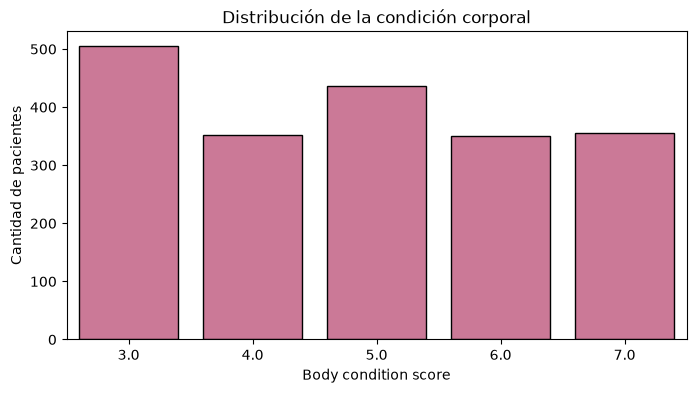

In [ ]:
graficar_barras(df, 'Body condition score',
               'Distribución de la condición corporal')

Interpretacion: Se identifica que la puntuación 3 es la más frecuente, seguida por la puntuación 5. Por otro lado, las puntuaciones 4, 6 y 7 presentan frecuencias relativamente similares.
Esta distribución permite conocer las características generales de la condición corporal de los pacientes. Sin embargo, al tratarse de un análisis univariado, no es posible determinar si alguna puntuación está relacionada con un mayor número de enfermedades.

### Distribucion de las variables categoricas
A continuación, analizaremos la distribución de las principales variables categóricas del dataset.

### Especie y sexo
Comenzando por la especie y el sexo de los pacientes.
Utilizaremos gráficos de barras, que permiten representar la frecuencia de cada categoría y comparar la cantidad de pacientes pertenecientes a cada grupo.
El objetivo es conocer la composición general del conjunto de datos e identificar posibles diferencias en la representación de las categorías.

In [ ]:

def plot_categoricas_univariado(df):
    '''
    Grafica la distribución de pacientes
    según especie y sexo.
    '''

    plt.figure(figsize=(12, 4))

    # Subplot de especies
    plt.subplot(1, 2, 1)
    sns.countplot(data=df, x='species',
                  color='#d96b93', edgecolor='black')
    plt.title('Distribución por especie')
    plt.xlabel('Especie')
    plt.ylabel('Cantidad de pacientes')

    # Subplot de sexo
    plt.subplot(1, 2, 2)
    sns.countplot(data=df, x='sex',
                  color='#e8a1be', edgecolor='black')
    plt.title('Distribución por sexo')
    plt.xlabel('Sexo')
    plt.ylabel('Cantidad de pacientes')

    plt.suptitle(
        'Distribución de las variables especie y sexo',
        fontsize=14,
        ha='center'
    )

    plt.tight_layout()
    plt.show()


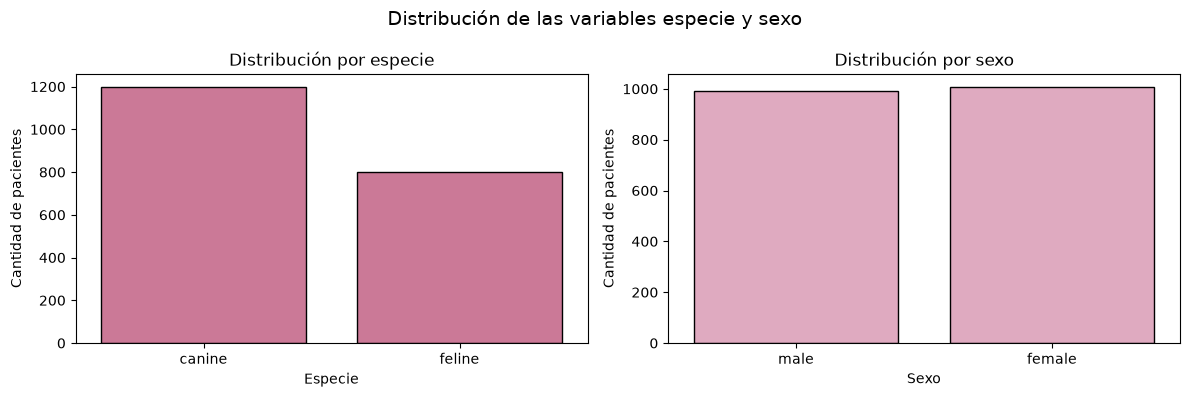

In [ ]:
plot_categoricas_univariado(df)

Interpretacion: A partir de los gráficos de barras, se observa que el conjunto de datos presenta una mayor proporción de pacientes caninos (60 %) que felinos (40 %).
En cuanto al sexo, la distribución es relativamente equilibrada, con cantidades similares de machos y hembras.

### Frecuencia de las distintas razas
Acontinuación, analizaremos la distribución de los pacientes según su raza, utilizando un gráfico de barras horizontales para facilitar la visualización y comparación de las distintas categorías.
El objetivo es identificar cuáles son las razas más representadas en el conjunto de datos y observar si existen diferencias importantes en la cantidad de pacientes registrados por raza.

In [ ]:

def plot_razas_univariado(df):
    '''
    Grafica la cantidad de pacientes por raza.
    '''

    plt.figure(figsize=(10, 6))

    sns.countplot(data=df, y='breed',
                  color='#d96b93', edgecolor='black')

    plt.title('Distribución de los pacientes según su raza')
    plt.xlabel('Cantidad de pacientes')
    plt.ylabel('Raza')

    plt.tight_layout()
    plt.show()


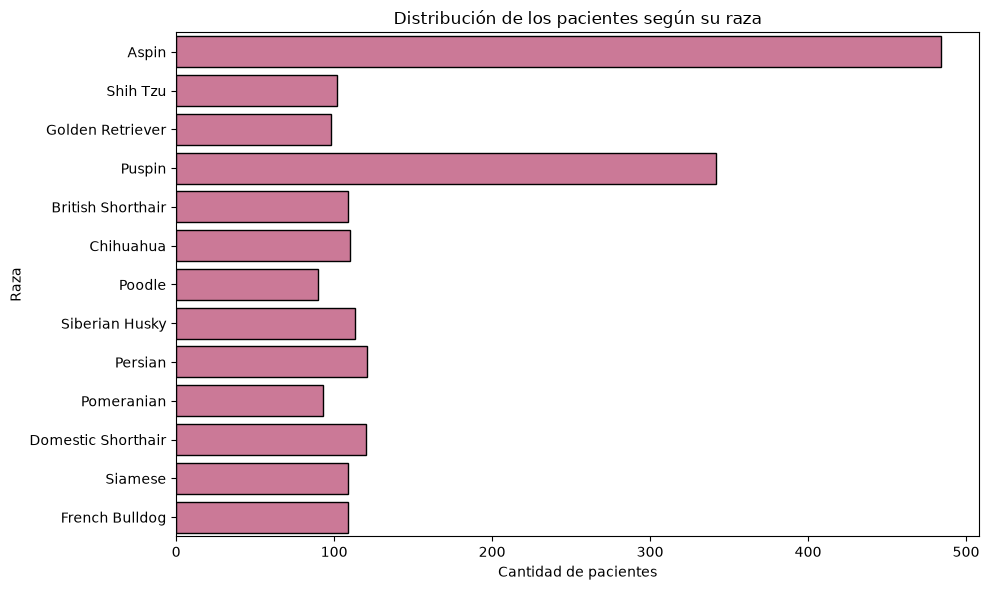

In [ ]:
plot_razas_univariado(df)

Interpretacion: Se identifica que Aspin y Puspin son las categorías con mayor cantidad de pacientes, mientras que las demás razas presentan frecuencias relativamente similares y considerablemente menores.
Esto evidencia una distribución desigual de los pacientes según su raza, con una mayor representación de determinadas categorías dentro del dataset.

### Resultados de la lampara de Wood
Esta prueba se utiliza para la detección de determinadas infecciones fúngicas. Por este motivo, consideramos que puede resultar relevante para nuestro objetivo predictivo, especialmente al analizar las enfermedades de piel.
Utilizaremos un gráfico de barras para visualizar la cantidad de pacientes con resultados positivos y negativos.

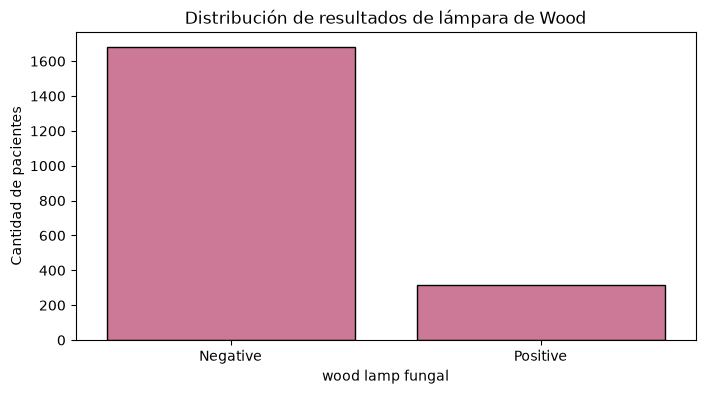

In [ ]:

graficar_barras(df, 'wood lamp fungal',
                'Distribución de resultados de lámpara de Wood')


Interpretacion: El gráfico de barras muestra un claro predominio de resultados negativos en la prueba de lámpara de Wood, mientras que los resultados positivos representan una proporción considerablemente menor del conjunto de datos.
Esta distribución permite conocer la frecuencia de los resultados registrados. Sin embargo, un resultado negativo no implica necesariamente que el paciente esté sano o que no presente una enfermedad dermatológica.

## Analisis Bivariado
Una vez analizadas las variables de manera individual, continuaremos con un análisis bivariado para investigar las posibles relaciones entre distintas características de los pacientes.
El objetivo de esta etapa es identificar patrones que puedan resultar relevantes para el modelo predictivo.

### Relacion entre peso y frecuencia cardiaca
Analizamos la relación entre el peso y la frecuencia cardíaca de los pacientes veterinarios mediante un gráfico de dispersión (scatterplot).
Además, diferenciaremos a los pacientes según su especie, con el objetivo de observar posibles patrones entre caninos y felinos.

In [ ]:

def plot_scatter_peso_frecuencia(df):
    '''
    Grafica la relación entre peso y frecuencia cardíaca,
    diferenciando a los pacientes según su especie.
    '''

    plt.figure(figsize=(10, 5))

    sns.scatterplot(data=df, x='weight', y='heart rate',
                    hue='species',
                    palette={'canine': '#d96b93',
                             'feline': '#e8a1be'})

    plt.title('Relación entre peso y frecuencia cardíaca')
    plt.xlabel('Peso (kg)')
    plt.ylabel('Frecuencia cardíaca (lpm)')

    plt.tight_layout()
    plt.show()


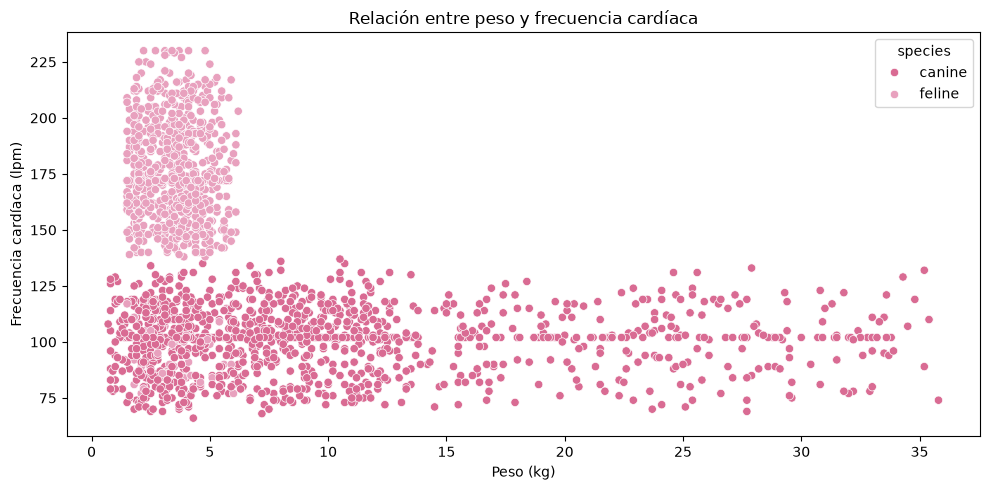

In [ ]:
plot_scatter_peso_frecuencia(df)

Interpretación: Por un lado, los felinos presentan una distribución de peso más concentrada, principalmente entre los 2 y 6 kg. Sin embargo, sus frecuencias cardíacas se distribuyen en un intervalo relativamente amplio, aproximadamente entre 140 y 230 latidos por minuto (lpm).
Por otro lado, los caninos presentan una mayor variabilidad en su peso, con valores que van desde aproximadamente 1 kg hasta superar los 35 kg. En cambio, sus frecuencias cardíacas se concentran mayormente entre 70 y 135 lpm.
Estas observaciones permiten identificar que los felinos presentan, en general, frecuencias cardíacas más elevadas que los caninos, a pesar de tener pesos menores. Esto sugiere que la especie podría ser un factor importante al analizar la relación entre ambas variables.
A partir de estos resultados surge una nueva pregunta: ¿las diferencias observadas en la frecuencia cardíaca responden a características propias de cada especie o podrían estar relacionadas con el estado de salud de los pacientes?

### Relacion entre la frecuencia cardiaca y el estado de salud
Analizaremos si existen diferencias en la frecuencia cardíaca entre pacientes sanos y enfermos, distinguiendo entre caninos y felinos.
Utilizaremos diagramas de boxplots para comparar las medianas, la dispersión y los rangos de frecuencia cardíaca de ambos grupos.
Esta comparación permitirá investigar si la frecuencia cardíaca presenta patrones asociados al estado de salud y si estos varían según la especie, con el objetivo de evaluar su posible utilidad para el modelo predictivo.

In [ ]:
def plot_variable_estado(df, columna, titulo, etiqueta_y):
    '''
    Compara una variable numérica entre animales sanos
    y enfermos, diferenciando caninos y felinos.
    '''

    # Seleccionamos las columnas necesarias
    datos = df[['species', columna, 'estado_salud']].copy()

    plt.figure(figsize=(12, 5))

    # Boxplot de caninos
    plt.subplot(1, 2, 1)
    sns.boxplot(
        data=datos[datos['species'] == 'canine'],
        x='estado_salud',
        y=columna,
        order=['sano', 'enfermo'],
        color='#d96b93'
    )

    plt.title('Caninos')
    plt.xlabel('Estado de salud')
    plt.ylabel(etiqueta_y)

    # Boxplot de felinos
    plt.subplot(1, 2, 2)
    sns.boxplot(
        data=datos[datos['species'] == 'feline'],
        x='estado_salud',
        y=columna,
        order=['sano', 'enfermo'],
        color='#e8a1be'
    )

    plt.title('Felinos')
    plt.xlabel('Estado de salud')
    plt.ylabel(etiqueta_y)

    plt.suptitle(titulo, fontsize=14)

    plt.tight_layout()
    plt.show()


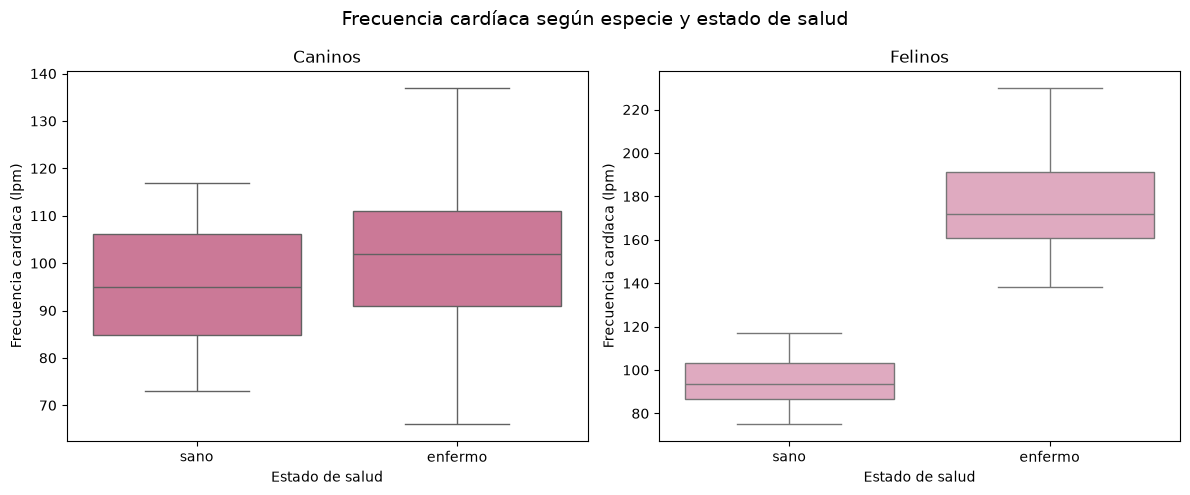

In [ ]:
plot_variable_estado(
    df,
    'heart rate',
    'Frecuencia cardíaca según especie y estado de salud',
    'Frecuencia cardíaca (lpm)'
)

Interpretación: En los caninos, los pacientes enfermos presentan una mediana ligeramente superior a la de los sanos. Sin embargo, existe una superposición considerable entre ambas distribuciones, lo que sugiere que la frecuencia cardíaca, por sí sola, podría no ser suficiente para distinguir ambos grupos.
En los felinos, se observa una diferencia mucho más marcada. Los pacientes clasificados como enfermos presentan frecuencias cardíacas considerablemente superiores a las de los sanos, sin que se observe superposición entre los rangos representados en el gráfico.
Estos resultados sugieren que la relación entre frecuencia cardíaca y estado de salud podría variar según la especie, por lo que ambas variables podrían ser relevantes para el modelo predictivo.

### Relacion entre la temperatura corporal y el estado de salud
Ahora analizamos la distribución de la temperatura corporal de los pacientes según su estado de salud, diferenciando entre caninos y felinos.
Reutilizaremos la función de boxplots definida anteriormente, que nos permitirá comparar las medianas y la dispersión de las temperaturas entre animales sanos y enfermos.
El objetivo es investigar si existen diferencias en la temperatura corporal asociadas al estado de salud y evaluar si esta variable podría aportar información relevante para el modelo predictivo.

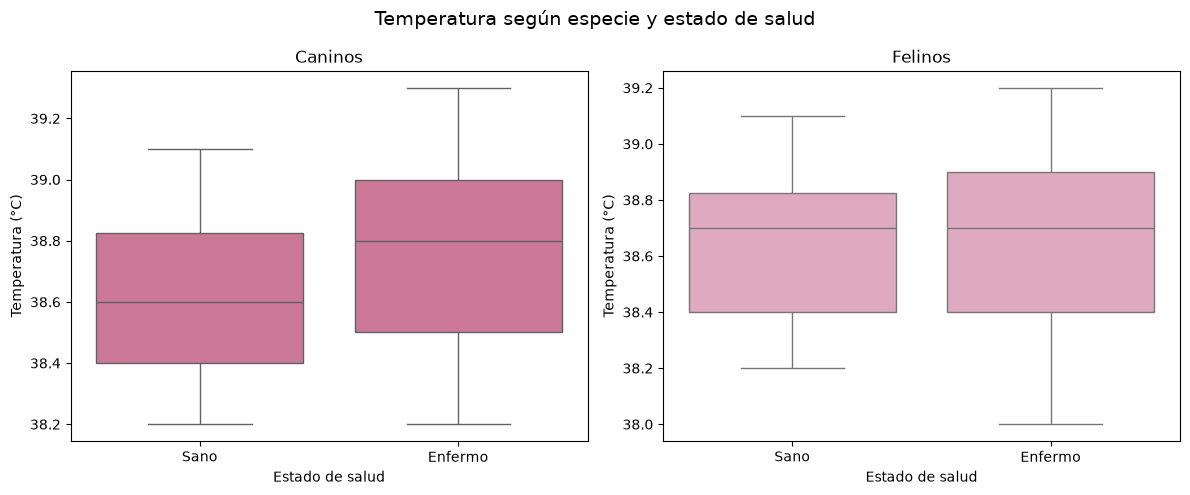

In [ ]:
plot_variable_estado(
    df,
    'temperature',
    'Temperatura según especie y estado de salud',
    'Temperatura (°C)'
)

Interpretación: En los caninos, los pacientes enfermos presentan una mediana ligeramente superior a la de los sanos. Sin embargo, existe una superposición considerable entre ambas distribuciones.
En los felinos, las medianas de los pacientes sanos y enfermos son prácticamente iguales, y sus distribuciones también presentan un importante solapamiento.
Estos resultados sugieren que la temperatura corporal, considerada de manera aislada, podría tener una utilidad limitada para distinguir animales sanos y enfermos dentro del conjunto de datos.
A diferencia de lo observado con la frecuencia cardíaca, especialmente en los felinos, la temperatura no presenta diferencias visualmente marcadas entre los estados de salud. Sin embargo, esto no significa que deba descartarse como variable predictora, ya que podría aportar información al combinarse con otras características de los pacientes.

### Relacion entre edad y el estado de salud 

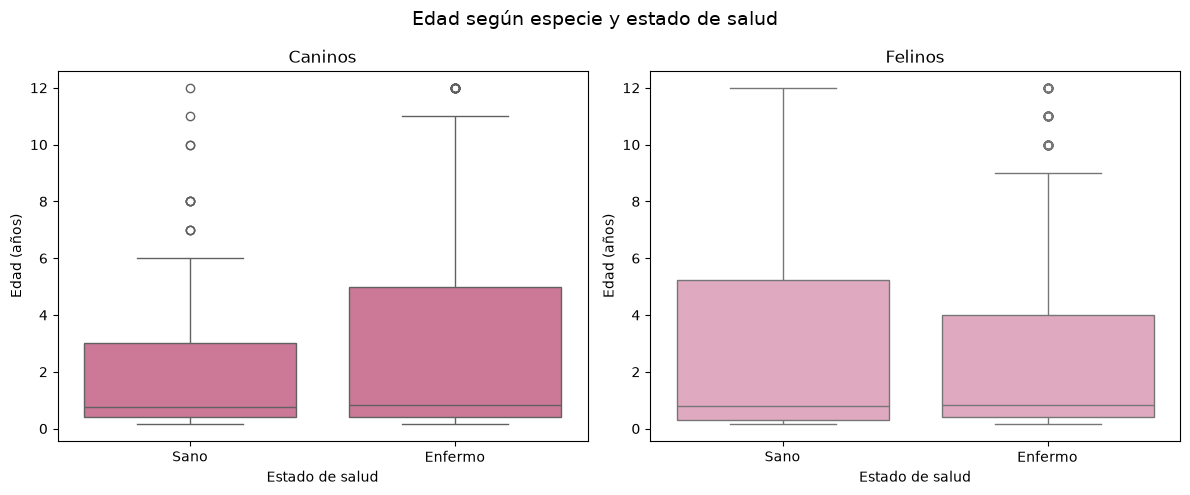

In [ ]:
plot_variable_estado(
    df,
    'age',
    'Edad según especie y estado de salud',
    'Edad (años)'
)


Interpretacion: A partir de los boxplots, se observa que las medianas de edad de los pacientes sanos y enfermos son relativamente similares tanto en caninos como en felinos, aunque existen diferencias en la dispersión de sus distribuciones.
En los caninos, los pacientes enfermos presentan una mayor dispersión de edades dentro del 50 % central de las observaciones, mientras que los sanos muestran una distribución más concentrada en edades jóvenes. Además, se identifican posibles valores atípicos correspondientes a animales de mayor edad.
En los felinos, se observa una situación diferente: los pacientes sanos presentan una dispersión ligeramente mayor que los enfermos, aunque las medianas se mantienen próximas. También se identifican posibles valores atípicos en edades elevadas.
En ambos casos, las distribuciones presentan una superposición considerable, por lo que la edad, considerada de manera aislada, no parece permitir una diferenciación clara entre animales sanos y enfermos.

### Relación entre los resultados de la lámpara de Wood y el estado de salud
La lámpara de Wood es una prueba clínica utilizada para detectar determinadas infecciones fúngicas, por lo que resulta interesante explorar su relación con el estado de salud de los pacientes.
Mediante un gráfico de barras agrupadas, compararemos la frecuencia de resultados positivos y negativos entre animales sanos y enfermos, buscando identificar posibles asociaciones entre ambas variables.

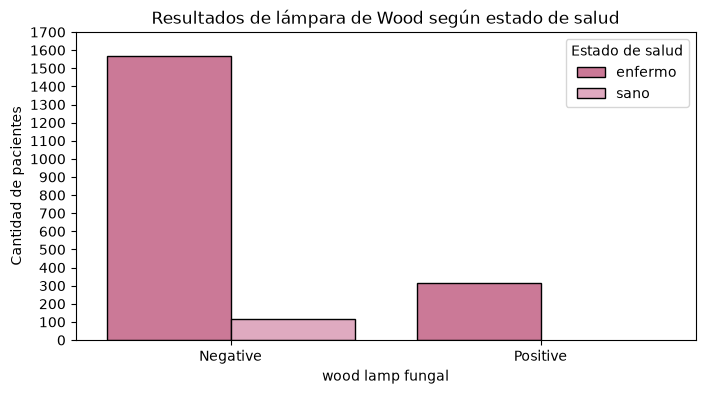

In [ ]:
graficar_barras(
    df,
    'wood lamp fungal',
    'Resultados de lámpara de Wood según estado de salud',
    hue='estado_salud',
    paso_y=100,
    paleta={'enfermo': '#d96b93', 'sano': '#e8a1be'}
)



Interpretacion: Se identifica que todos los pacientes con resultado positivo aparecen clasificados como enfermos. Sin embargo, también se observa una cantidad considerable de animales enfermos entre aquellos que obtuvieron un resultado negativo.
Esto sugiere que un resultado positivo podría aportar información relevante para identificar determinados pacientes enfermos dentro del conjunto de datos, mientras que un resultado negativo no implica necesariamente que el animal esté sano.

### Relacion entre condición corporal según especie y estado de salud
La condición corporal es una característica que podría aportar información sobre el estado general de los pacientes veterinarios.
Aquí ompararemos las puntuaciones de condición corporal entre animales sanos y enfermos, distinguiendo entre caninos y felinos. Mediante diagramas de caja y bigotes, examinaremos si existen diferencias en las medianas y la dispersión de las puntuaciones, con el propósito de identificar posibles patrones asociados al estado de salud.

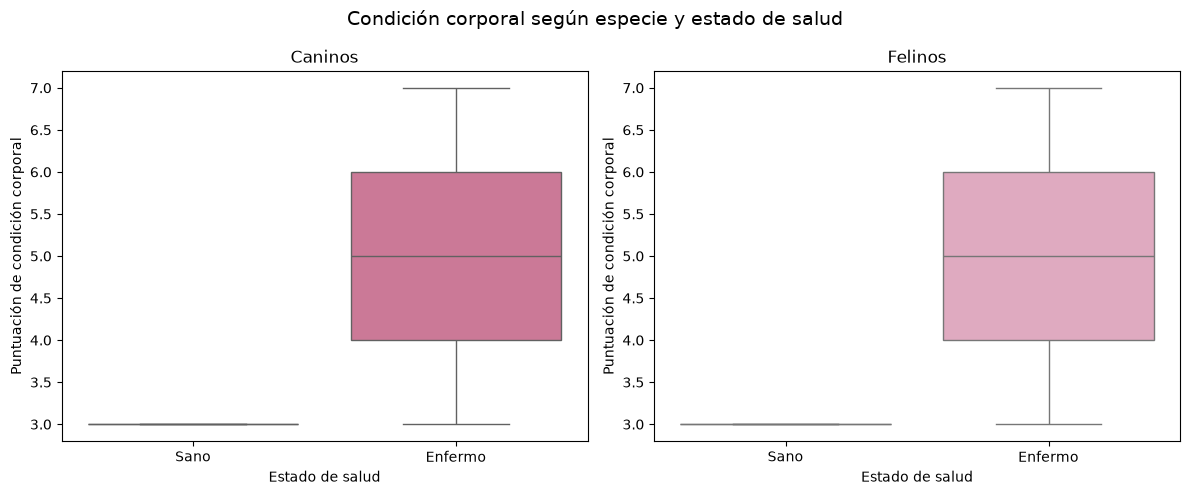

In [ ]:

plot_variable_estado(
    df,
    'Body condition score',
    'Condición corporal según especie y estado de salud',
    'Puntuación de condición corporal'
)


Interpretacion: A partir de los boxplots, se observa una diferencia marcada en la distribución de las puntuaciones de condición corporal entre los pacientes sanos y enfermos.
Tanto en caninos como en felinos, los pacientes clasificados como sanos presentan una puntuación de condición corporal de 3, sin variabilidad visible.
En cambio, los pacientes enfermos presentan una mayor dispersión, con puntuaciones comprendidas entre 3 y 7 y una mediana cercana a 5 en ambas especies.
Estos resultados sugieren que la condición corporal podría aportar información relevante para distinguir el estado de salud de los pacientes. Sin embargo, una puntuación de 3 no garantiza que el animal esté sano, ya que también se registra entre los enfermos.

### Relación entre estado de salud y situcion de tenencia
La situación de tenencia de los pacientes es otra de las variables que consideramos relevante investigar, ya que podría presentar alguna asociación con su estado de salud.
Para explorar esta relación, utilizaremos un gráfico de barras agrupadas que nos permitirá comparar la cantidad de animales sanos y enfermos según su condición de tenencia: aquellos que tienen dueño (owned), los rescatados (rescued) y los registrados como perdidos y posteriormente rescatados (lost_rescued).

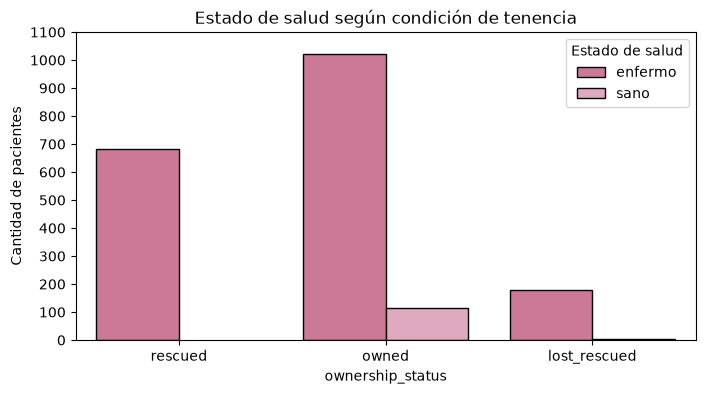

In [ ]:

# Seleccionamos las columnas necesarias para el análisis
datos = df[['ownership_status', 'estado_salud']].copy()

# Graficamos el estado de salud según la condición de tenencia
graficar_barras(
    datos,
    'ownership_status',
    'Estado de salud según condición de tenencia',
    hue='estado_salud',
    paso_y=100,
    paleta={'enfermo': '#d96b93', 'sano': '#e8a1be'}
)


Interpretación: El gráfico de barras agrupadas permite observar la distribución de pacientes sanos y enfermos según su condición de tenencia.
Se identifica un predominio de pacientes enfermos en las tres categorías, siendo especialmente marcada esta diferencia en los animales rescatados y en aquellos registrados como lost_rescued.
Estos resultados plantean la posibilidad de una asociación entre la condición de tenencia y el estado de salud. Sin embargo, será necesario comparar las proporciones de pacientes enfermos dentro de cada grupo y verificar la consistencia de los datos antes de establecer conclusiones definitivas.

### Análisis de correlación entre variables numéricas
Ahora calculamos la matriz de correlaciones de Pearson entre las principales variables numéricas del dataset: peso, temperatura, frecuencia cardíaca, edad y condición corporal.
Posteriormente, representamos los coeficientes mediante un mapa de calor (heatmap) para facilitar la identificación de posibles relaciones lineales entre estas características clínicas.

In [ ]:

# Seleccionamos las variables numéricas relevantes
variables_numericas = [
    'age',
    'weight',
    'temperature',
    'heart rate',
    'Body condition score'
]

# Calculamos la matriz de correlaciones
corr_matrix = df[variables_numericas].corr()

corr_matrix


,age,weight,temperature,heart rate,Body condition score
age,1.000000,0.149847,-0.007351,0.001839,0.036794
weight,0.149847,1.000000,0.062153,-0.391170,0.008476
temperature,-0.007351,0.062153,1.000000,-0.117453,-0.006544
heart rate,0.001839,-0.391170,-0.117453,1.000000,0.097506
Body condition score,0.036794,0.008476,-0.006544,0.097506,1.000000


In [ ]:

def plot_mapa_calor(corr_matrix):
    '''
    Grafica el mapa de calor de las correlaciones
    entre variables numéricas.
    '''

    plt.figure(figsize=(8, 6))

    sns.heatmap(corr_matrix, annot=True, cmap='RdPu',
                vmin=-1, vmax=1, fmt='.2f')

    plt.title('Mapa de calor de correlaciones')

    plt.tight_layout()
    plt.show()


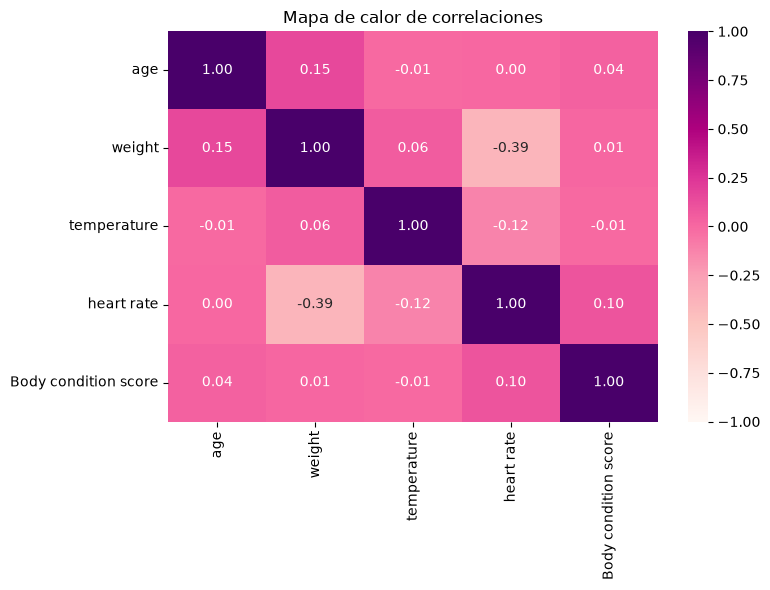

In [ ]:
plot_mapa_calor(corr_matrix)

Interpretacion: A partir de la matriz de correlaciones de Pearson, se observa que la mayoría de las variables numéricas presentan asociaciones lineales muy débiles o prácticamente nulas.
La relación más destacada corresponde al peso y la frecuencia cardíaca, con un coeficiente aproximado de −0,345, lo que indica una correlación negativa débil. Esto sugiere que, dentro del conjunto de datos, los pacientes de mayor peso tienden a presentar frecuencias cardíacas menores.
Sin embargo, esta relación podría estar influida por las diferencias entre especies, ya que anteriormente observamos que los felinos presentan, en general, pesos menores y frecuencias cardíacas superiores a las de los caninos.
Por otro lado, la edad presenta correlaciones muy bajas con las demás variables numéricas. Su asociación más elevada corresponde al peso (r ≈ 0,15), mientras que con la temperatura, la frecuencia cardíaca y la condición corporal los coeficientes son cercanos a cero.
En general, no se identifican correlaciones lineales fuertes entre las características numéricas analizadas.

# Agrupaciones y Visualizaciones:
En esta primera etapa de análisis bivariado, nos propusimos agrupar y clasificar los diagnósticos definitivos de los pacientes para examinar la frecuencia de las principales patologías en función de la especie. El objetivo de este procedimiento es identificar la distribución global de las afecciones clínicas en el dataset, permitiendo visualizar qué tipo de patologías predominan tanto en caninos como en felinos antes de profundizar en las pruebas de laboratorio específicas.
Más abajo se presentarán tres ejes analíticos fundamentales: en primer lugar, el cruce entre la condición de tenencia y el estado de salud general de los pacientes; en segundo término, la evaluación del rendimiento de la prueba de la lámpara de Wood frente a las patologías cutáneas; y por último, el estudio comparativo de las constantes fisiológicas de frecuencia cardíaca segmentadas por especie y condición clínica.

In [ ]:
# 1. Función para agrupar los diagnósticos según el objetivo del modelo
def clasificar_patologia(diag):
  if diag == 'healthy':
    return 'Sano'

  es_piel = any(term in diag for term in ['Dermatitis', 'Ringworm'])
  es_otico = any(term in diag for term in ['Otitis', 'Ear Mites'])

  if es_piel and es_otico:
    return 'Piel y Ótico (Mixto)'
  elif es_piel:
    return 'Afección de Piel'
  elif es_otico:
    return 'Afección Ótica'
  else:
    return 'Otro'


df['categoria_diagnostico'] = df['definitive diagnosis'].apply(
    clasificar_patologia
)

# 2. groupby + agg para calcular métricas por especie y categoría
df_agrupado = (
    df.groupby(['species', 'categoria_diagnostico'])
    .agg(
        cantidad_pacientes=('species', 'count'),
        peso_promedio=('weight', 'mean'),
    )
    .reset_index()
)

print('Resultado de la agregación (groupby + agg):')
display(df_agrupado)

Resultado de la agregación (groupby + agg):


,species,categoria_diagnostico,cantidad_pacientes,peso_promedio
0,canine,Afección de Piel,363,9.956198
1,canine,Afección Ótica,389,10.648072
2,canine,Piel y Ótico (Mixto),375,10.637333
3,canine,Sano,72,10.075000
4,feline,Afección de Piel,268,3.555970
5,feline,Afección Ótica,255,3.521961
6,feline,Piel y Ótico (Mixto),234,3.555556
7,feline,Sano,44,3.422727


#### Gráfico de distribución de diagnósticos:

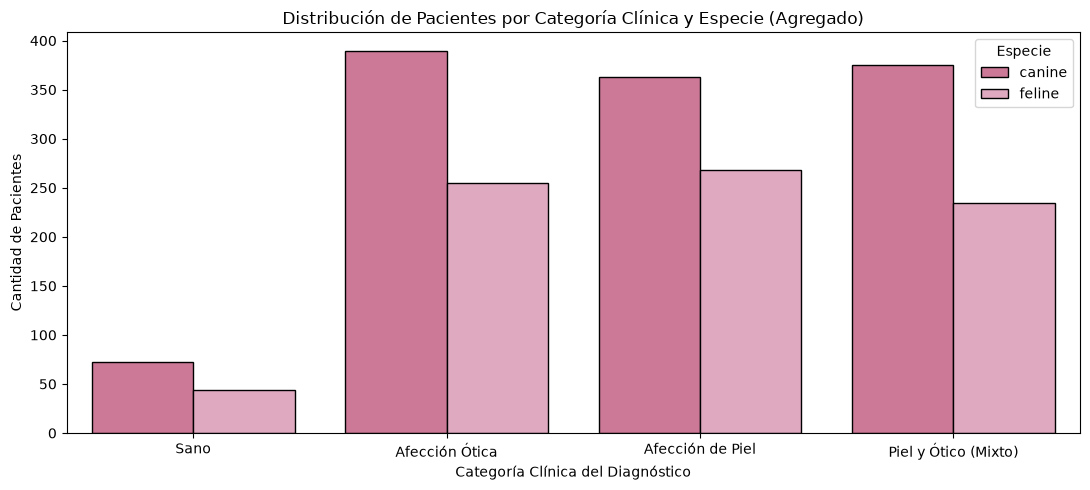

In [ ]:
# 3. Barplot basado en la agregación para ver el cruce de variables útil
plt.figure(figsize=(11, 5))
sns.barplot(
    data= df_agrupado,
    x='categoria_diagnostico',
    y='cantidad_pacientes',
    hue='species',
    order=['Sano', 'Afección Ótica', 'Afección de Piel', 'Piel y Ótico (Mixto)'],
    palette={'canine': '#d96b93', 'feline': '#e8a1be'},
    edgecolor='black',
)

plt.title(
    'Distribución de Pacientes por Categoría Clínica y Especie (Agregado)',
    fontsize=12,
)
plt.xlabel('Categoría Clínica del Diagnóstico', fontsize=10)
plt.ylabel('Cantidad de Pacientes', fontsize=10)
plt.legend(title='Especie')
plt.tight_layout()
plt.show()

### Interpretación de Hallazgos y Análisis del Modelo Predictivo
 Tras agrupar los diagnósticos definitivos según el objetivo analítico del modelo, se observa que la Afección Ótica (389 en caninos y 255 en felinos) y los casos Mixtos de Piel y Ótico (375 en caninos y 234 en felinos) concentran el mayor volumen de consultas en la veterinaria, seguidos muy de cerca por las Afecciones de Piel puras (363 en caninos y 268 en felinos). Los pacientes registrados como sanos representan una minoría proporcional en el dataset (72 caninos y 44 felinos).

Los caninos concentran el mayor volumen total de casos en todas las categorías clínicas en comparación con los felinos. Sin embargo, la proporción de distribución entre patologías se mantiene equilibrada en ambas especies, destacando un fuerte solapamiento entre problemas óticos y dermatológicos (casos mixtos).

### Justificación sobre la Serie Temporal:
¿Es posible armar una serie temporal? No para los fines analíticos del modelo predictivo.

Motivo: 
Una serie temporal busca proyectar eventos en el tiempo (tendencias o estacionalidades futuras), lo cual no aporta valor ni guarda relación biológica con el objetivo central del programa. El propósito de nuestro modelo de clasificación (KNN) es predecir el estado de salud y la patología clínica (ótica, de piel o mixta) en función de las características biométricas y signos vitales del paciente al momento de la consulta. Por lo tanto, el enfoque temporal se omite del modelado por una decisión estrictamente analítica y de diseño del algoritmo, priorizando por completo el perfil clínico de los animales.

## Análisis de Variables Clínicas, Demográficas y Pruebas de Apoyo en la Población Veterinaria
### Análisis Bivariado: Proporción del Estado de Salud según el Origen del Animal
En el análisis exploratorio identificamos diferencias en la cantidad de pacientes sanos y enfermos
según su situación de tenencia.
Sin embargo, como las categorías presentan distintos tamaños, las frecuencias absolutas no permiten comparar directamente el peso de cada estado de salud dentro de los grupos.
Por este motivo, calcularemos la proporción de animales sanos y enfermos en cada categoría de tenencia y la representaremos mediante un gráfico de barras apiladas al 100 %.

In [ ]:
if 'estado_salud' not in df.columns:
    df['estado_salud'] = df['definitive diagnosis'].apply(lambda x: 'sano' if x == 'healthy' else 'enfermo')

# Agrupación por ownership_status y estado_salud usando .size() 
resumen_tenencia = df.groupby(['ownership_status', 'estado_salud']).size().reset_index(name='cantidad_pacientes')

# Calculamos el total por cada grupo de tenencia para sacar el porcentaje
total_por_tenencia = df.groupby('ownership_status').size().reset_index(name='total_grupo')
resumen_tenencia = resumen_tenencia.merge(total_por_tenencia, on='ownership_status')
resumen_tenencia['porcentaje'] = (resumen_tenencia['cantidad_pacientes'] / resumen_tenencia['total_grupo']) * 100

display(resumen_tenencia)

,ownership_status,estado_salud,cantidad_pacientes,total_grupo,porcentaje
0,lost_rescued,enfermo,179,182,98.351648
1,lost_rescued,sano,3,182,1.648352
2,owned,enfermo,1021,1134,90.035273
3,owned,sano,113,1134,9.964727
4,rescued,enfermo,684,684,100.000000


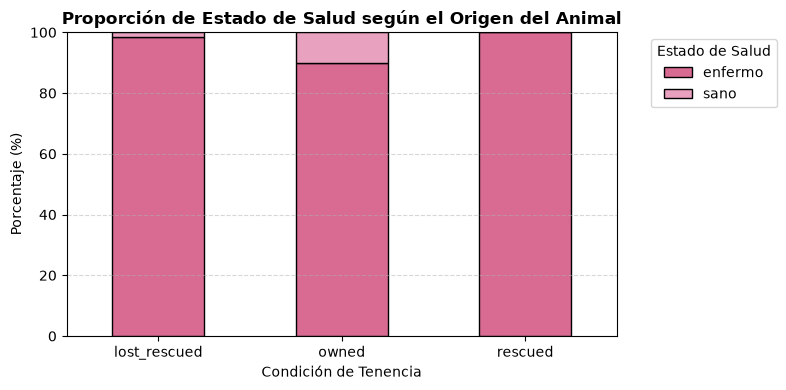

In [ ]:
# Gráfico de barras 100% apilado para visualizar la proporción de sanos/enfermos por tenencia
cross_tenencia = pd.crosstab(df['ownership_status'], df['estado_salud'], normalize='index') * 100

cross_tenencia.plot(kind='bar', stacked=True, color=['#d96b93', '#e8a1be'], edgecolor='black', figsize=(8, 4))
plt.title('Proporción de Estado de Salud según el Origen del Animal', fontsize=12, fontweight='bold')
plt.xlabel('Condición de Tenencia', fontsize=10)
plt.ylabel('Porcentaje (%)', fontsize=10)
plt.legend(title='Estado de Salud', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

#### Conclusiones
A diferencia de los recuentos absolutos previos, normalizar las proporciones dentro de cada categoría de tenencia permite neutralizar la diferencia de tamaño entre los grupos (ya que existen más animales con dueño que rescatados), evidenciando de forma equitativa que los animales con dueño concentran una pequeña proporción de casos catalogados como sanos (cerca del 10%), mientras que en los grupos de animales rescatados y perdidos la gran mayoría de los ingresos se registran bajo cuadros de enfermedad. Esto demuestra que la condición de tenencia actúa como un indicador contextual fuerte y un criterio descriptivo sumamente útil para respaldar el comportamiento de la salud de los pacientes en el modelo predictivo.

### Evaluación de la Prueba Diagnóstica de Lámpara de Wood según las Patologías Cutáneas y Óticas
En esta instancia del análisis exploratorio, nos propusimos cruzar los resultados de la prueba de la lámpara de Wood con los principales tipos de afecciones de los pacientes enfermos. Este procedimiento se realizó con el fin de examinar el rendimiento y la especificidad de dicha prueba diagnóstica, evaluando si actúa como un indicador clínico diferencial confiable para respaldar al modelo predictivo en la distinción de patologías cutáneas frente a cuadros óticos. Mientras que en las secciones previas se evaluó el test de forma global, en este apartado profundizamos específicamente en la población de pacientes enfermos para analizar las particularidades de esta prueba en relación exclusiva con las patologías cutáneas y mixtas.

In [ ]:
# Filtramos solo los pacientes enfermos y clasificamos la afección principal
enfermos = df[df['estado_salud'] == 'enfermo'].copy()

def clasificar_afeccion(diag):
    diag_lower = diag.lower()
    tiene_piel = 'dermatitis' in diag_lower or 'ringworm' in diag_lower
    tiene_otitis = 'otitis' in diag_lower or 'mites' in diag_lower
    
    if tiene_piel and tiene_otitis:
        return 'Ambas (Piel y Otitis)'
    elif tiene_piel:
        return 'Enfermedad de Piel'
    elif tiene_otitis:
        return 'Otitis'
    else:
        return 'Otro'

enfermos['tipo_afeccion'] = enfermos['definitive diagnosis'].apply(clasificar_afeccion)

# Agrupamos por tipo de afección y resultado de la lámpara de Wood
resumen_lampara = enfermos.groupby(['tipo_afeccion', 'wood lamp fungal']).size().reset_index(name='cantidad')

# Calculamos porcentajes dentro de cada tipo de afeccion
total_afecion = enfermos.groupby('tipo_afeccion').size().reset_index(name='total_afecion')
resumen_lampara = resumen_lampara.merge(total_afecion, on='tipo_afeccion')
resumen_lampara['porcentaje'] = (resumen_lampara['cantidad'] / resumen_lampara['total_afecion']) * 100

display(resumen_lampara)

,tipo_afeccion,wood lamp fungal,cantidad,total_afecion,porcentaje
0,Ambas (Piel y Otitis),Negative,433,609,71.100164
1,Ambas (Piel y Otitis),Positive,176,609,28.899836
2,Enfermedad de Piel,Negative,490,631,77.654517
3,Enfermedad de Piel,Positive,141,631,22.345483
4,Otitis,Negative,644,644,100.000000


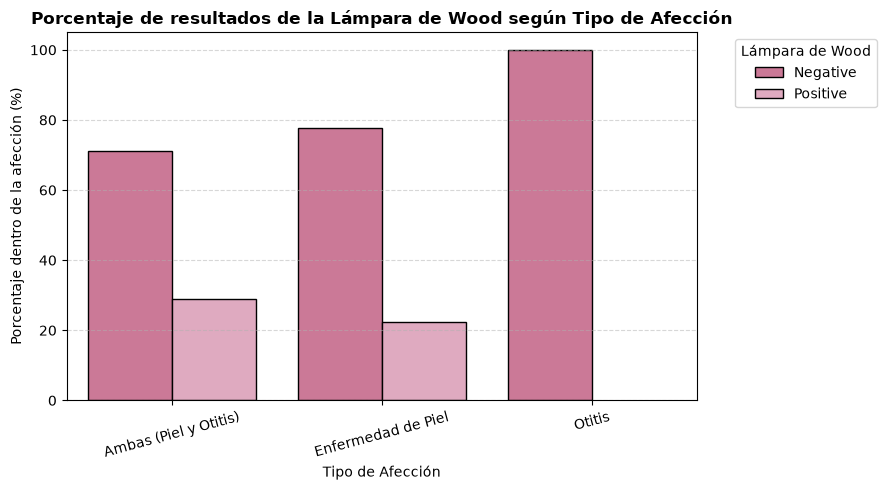

In [ ]:
# Gráfico para visualizar los resultados de la lámpara de Wood según el tipo de afección
plt.figure(figsize=(9, 5))
sns.barplot(
    data=resumen_lampara, 
    x='tipo_afeccion', 
    y='porcentaje', 
    hue='wood lamp fungal', 
    palette=['#d96b93', '#e8a1be'], 
    edgecolor='black'
)

plt.title('Porcentaje de resultados de la Lámpara de Wood según Tipo de Afección', fontsize=12, fontweight='bold')
plt.xlabel('Tipo de Afección', fontsize=10)
plt.ylabel('Porcentaje dentro de la afección (%)', fontsize=10)
plt.legend(title='Lámpara de Wood', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

#### Conclusiones
El gráfico expone de manera categórica que los resultados positivos de la lámpara de Wood se concentran exclusivamente en las patologías que involucran la piel (enfermedades cutáneas y cuadros mixtos), arrojando un 100% de negativos en pacientes con afecciones exclusivamente óticas. Esto demuestra que un resultado positivo funciona como un fuerte indicador de afección cutánea, mientras que el resultado negativo requiere complementarse con otras variables. De este modo, la clara segmentación confirma que la variable posee un gran valor clínico y aporta una base sólida para que el algoritmo k-NN logre clasificar las patologías sin generar ruido innecesario.

### Análisis Multivariado: Distribución de la Frecuencia Cardíaca según Especie y Estado de Salud
En esta parte del análisis exploratorio, agrupamos y analizamos la frecuencia cardíaca de los pacientes dividiéndola por especie y estado de salud. Este procedimiento se realizó con el objetivo de identificar patrones fisiológicos diferenciales y comprobar cómo varían los signos vitales entre caninos y felinos, respaldando de forma empírica la decisión técnica de realizar una imputación de nulos segmentada para este parámetro clínico. Complementando la exploración visual de las distribuciones de signos vitales, formalizamos a continuación un resumen estadístico desagregado (mediana, mínimos y máximos) para dimensionar con precisión la dispersión y el rango fisiológico de los latidos por minuto en cada subgrupo de pacientes.

In [ ]:
# Agrupación por especie y estado de salud calculando estadísticas de heart rate
resumen_hr = df.groupby(['species', 'estado_salud']).agg(
    cantidad_pacientes=('species', 'count'),
    mediana_hr=('heart rate', 'median'),
    min_hr=('heart rate', 'min'),
    max_hr=('heart rate', 'max')
).reset_index()

display(resumen_hr)

,species,estado_salud,cantidad_pacientes,mediana_hr,min_hr,max_hr
0,canine,enfermo,1127,103.0,66.0,137.0
1,canine,sano,72,95.0,73.0,117.0
2,feline,enfermo,757,174.0,138.0,230.0
3,feline,sano,44,93.5,75.0,117.0


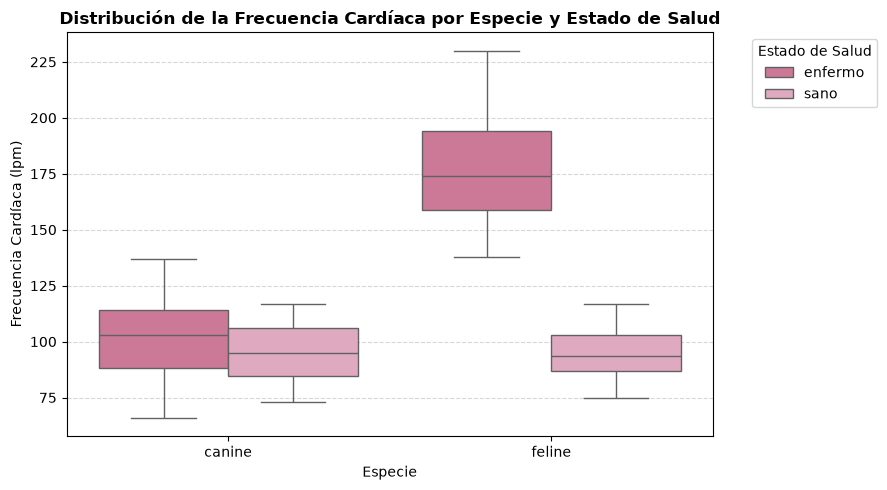

In [ ]:
plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df, 
    x='species', 
    y='heart rate', 
    hue='estado_salud', 
    palette=['#d96b93', '#e8a1be']
)

plt.title('Distribución de la Frecuencia Cardíaca por Especie y Estado de Salud', fontsize=12, fontweight='bold')
plt.xlabel('Especie', fontsize=10)
plt.ylabel('Frecuencia Cardíaca (lpm)', fontsize=10)
plt.legend(title='Estado de Salud', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

#### Conclusiones
El diagrama de caja revela una marcada diferencia fisiológica entre especies, donde los felinos presentan rangos y medianas de frecuencia cardíaca notablemente más elevados que los caninos. Asimismo, permite visualizar la dispersión y los límites de los latidos por minuto en los animales sanos frente a los enfermos, justificando la importancia de incorporar variables de signos vitales normalizadas para optimizar el rendimiento y las distancias espaciales del modelo k-NN.

## Modelo de clasificación con K-Nearest Neighbors (KNN)

### Definición del objetivo

El objetivo del modelo es predecir la categoría general del diagnóstico de un paciente a partir de sus características clínicas.

Para simplificar los diagnósticos originales, utilizamos la variable `categoria_diagnostico`, que construimos anteriormente agrupando los diagnósticos en cuatro categorías:

- Sano.
- Afección de Piel.
- Afección Ótica.
- Piel y Ótico (Mixto).

De esta manera, trabajamos con un problema de clasificación de cuatro clases, en lugar de intentar predecir cada uno de los diagnósticos originales por separado.

In [ ]:
# Observamos la cantidad de pacientes en cada categoría
df["categoria_diagnostico"].value_counts()

categoria_diagnostico
Afección Ótica          644
Afección de Piel        631
Piel y Ótico (Mixto)    609
Sano                    116
Name: count, dtype: int64

### Selección de variables predictoras (X) y variable objetivo (y)

Como variables predictoras seleccionamos características que pueden aportar información sobre el estado del paciente: edad, peso, temperatura, frecuencia cardíaca, condición corporal, especie, sexo y resultado de la lámpara de Wood.

Las variables categóricas se transforman a valores numéricos para que el algoritmo KNN pueda trabajar con ellas. La variable objetivo será `categoria_diagnostico`.

In [ ]:
# Variables predictoras
X = df[
    [
        "age",
        "weight",
        "temperature",
        "heart rate",
        "Body condition score"
    ]
].copy()

# Convertimos las variables categóricas seleccionadas a valores numéricos
X["species"] = (df["species"] == "canine").astype(int)
X["sex"] = (df["sex"] == "male").astype(int)
X["wood_lamp_positive"] = (df["wood lamp fungal"] == "Positive").astype(int)

# Variable objetivo
y = df["categoria_diagnostico"]

display(X.head())
display(y.value_counts())

,age,weight,temperature,heart rate,Body condition score,species,sex,wood_lamp_positive
0,4.000000,6.7,39.1,114.0,4.0,1,1,0
1,9.000000,9.7,39.1,102.0,4.0,1,1,0
2,0.230769,11.7,39.1,102.0,3.0,1,1,0
3,12.000000,4.1,38.7,172.0,3.0,0,0,0
4,3.000000,8.1,39.0,79.0,3.0,1,0,0


categoria_diagnostico
Afección Ótica          644
Afección de Piel        631
Piel y Ótico (Mixto)    609
Sano                    116
Name: count, dtype: int64

### División en conjunto de entrenamiento y prueba

Dividimos los datos en dos grupos: el 80 % se utiliza para entrenar el modelo y el 20 % para evaluar su rendimiento.

Utilizamos `stratify=y` para mantener aproximadamente la misma proporción de categorías en ambos conjuntos. Además, fijamos `random_state=42` para que la división pueda reproducirse.

In [ ]:
SEMILLA = 42

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEMILLA,
    stratify=y
)

print("Dimensiones de entrenamiento:", X_train.shape)
print("Dimensiones de prueba:", X_test.shape)

# Comparamos la distribución de las categorías en train y test
pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True)
}).round(3)

Dimensiones de entrenamiento: (1600, 8)
Dimensiones de prueba: (400, 8)


,train,test
categoria_diagnostico,,
Afección Ótica,0.322,0.322
Afección de Piel,0.316,0.315
Piel y Ótico (Mixto),0.304,0.305
Sano,0.058,0.058


### Modelo baseline

Antes de entrenar KNN, construimos un modelo de referencia o baseline. Este modelo predice siempre la categoría más frecuente del conjunto de entrenamiento.

Nos permite establecer un resultado mínimo de comparación: el modelo KNN debería superar este valor para demostrar que aprende información útil de las variables predictoras.

In [ ]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

y_pred_baseline = baseline.predict(X_test)
accuracy_baseline = accuracy_score(y_test, y_pred_baseline)

print(f"Accuracy del baseline: {accuracy_baseline:.1%}")

Accuracy del baseline: 32.2%


### Entrenamiento del modelo KNN

Utilizamos K-Nearest Neighbors (KNN), un algoritmo de clasificación que asigna una categoría a un nuevo caso según las categorías de sus vecinos más cercanos.

Como las variables tienen escalas diferentes (por ejemplo, peso, temperatura y frecuencia cardíaca), incorporamos `StandardScaler` dentro de un `Pipeline`. De esta manera, las variables se escalan antes de calcular las distancias y el escalado se ajusta solamente con los datos de entrenamiento.

In [ ]:
# Creamos un pipeline con escalado y el clasificador KNN
pipeline_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

# Entrenamos inicialmente con k=5
modelo_knn = pipeline_knn.set_params(knn__n_neighbors=5)
modelo_knn.fit(X_train, y_train)

y_pred_knn = modelo_knn.predict(X_test)

accuracy_knn = accuracy_score(y_test, y_pred_knn)

print(f"Accuracy del KNN con k=5: {accuracy_knn:.1%}")

Accuracy del KNN con k=5: 32.8%


### Elección de k mediante validación cruzada

El parámetro `k` representa la cantidad de vecinos que el algoritmo consulta para realizar una predicción. Para elegirlo, utilizamos `GridSearchCV`, que prueba diferentes valores de k y compara su rendimiento mediante validación cruzada.

Utilizamos cinco particiones (`StratifiedKFold`) para mantener la proporción de las clases en cada ronda. La búsqueda se realiza únicamente con el conjunto de entrenamiento, sin utilizar los datos de prueba.

In [ ]:
# Validación cruzada estratificada
kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEMILLA
)

# Valores de k que vamos a comparar
grilla = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31, 41, 51]
}

busqueda = GridSearchCV(
    pipeline_knn,
    grilla,
    cv=kfold,
    scoring="accuracy"
)

busqueda.fit(X_train, y_train)

print("Mejor parámetro:", busqueda.best_params_)
print(f"Accuracy promedio de validación: {busqueda.best_score_:.1%}")

Mejor parámetro: {'knn__n_neighbors': 51}
Accuracy promedio de validación: 40.1%


In [ ]:
# Evaluamos el mejor modelo sobre el conjunto de prueba
mejor_knn = busqueda.best_estimator_
y_pred_final = mejor_knn.predict(X_test)

accuracy_final = accuracy_score(y_test, y_pred_final)

print(f"Accuracy del baseline: {accuracy_baseline:.1%}")
print(f"Accuracy del KNN optimizado: {accuracy_final:.1%}")

Accuracy del baseline: 32.2%
Accuracy del KNN optimizado: 38.0%


### Evaluación del modelo: matriz de confusión y métricas

Comparamos las predicciones del modelo con los diagnósticos reales del conjunto de prueba. Utilizamos la matriz de confusión para identificar en qué categorías acierta y en cuáles se equivoca.

También calculamos `classification_report`, que incluye precision, recall y F1-score para cada categoría.

,Predicho: Sano,Predicho: Afección de Piel,Predicho: Afección Ótica,Predicho: Piel y Ótico (Mixto)
Real: Sano,2,2,14,5
Real: Afección de Piel,0,33,64,29
Real: Afección Ótica,0,37,82,10
Real: Piel y Ótico (Mixto),0,31,56,35


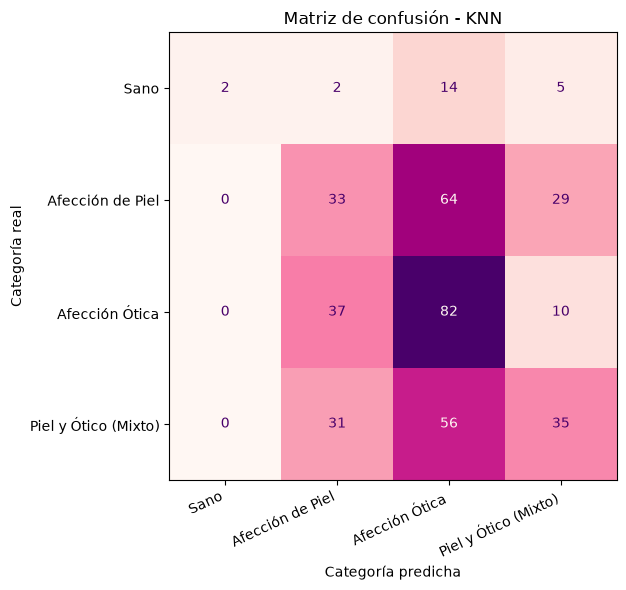

In [ ]:
orden_clases = [
    "Sano",
    "Afección de Piel",
    "Afección Ótica",
    "Piel y Ótico (Mixto)"
]

matriz = confusion_matrix(
    y_test,
    y_pred_final,
    labels=orden_clases
)

display(pd.DataFrame(
    matriz,
    index=[f"Real: {clase}" for clase in orden_clases],
    columns=[f"Predicho: {clase}" for clase in orden_clases]
))

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=orden_clases
).plot(ax=ax, cmap="RdPu", colorbar=False)

ax.set_title("Matriz de confusión - KNN")
ax.set_xlabel("Categoría predicha")
ax.set_ylabel("Categoría real")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
print(classification_report(
    y_test,
    y_pred_final,
    labels=orden_clases,
    zero_division=0
))

                      precision    recall  f1-score   support

                Sano       1.00      0.09      0.16        23
    Afección de Piel       0.32      0.26      0.29       126
      Afección Ótica       0.38      0.64      0.48       129
Piel y Ótico (Mixto)       0.44      0.29      0.35       122

            accuracy                           0.38       400
           macro avg       0.54      0.32      0.32       400
        weighted avg       0.42      0.38      0.36       400



In [ ]:
# Tabla de comparación entre el baseline y el modelo KNN
resultados_modelo = pd.DataFrame({
    "Modelo": ["Baseline", "KNN optimizado"],
    "Accuracy": [accuracy_baseline, accuracy_final]
})

display(resultados_modelo)

,Modelo,Accuracy
0,Baseline,0.3225
1,KNN optimizado,0.3800


### Interpretación de los resultados del modelo

El baseline obtuvo un accuracy del **32,25 %**, mientras que el modelo KNN optimizado alcanzó un accuracy del **38 %** en el conjunto de prueba. Por lo tanto, el modelo supera al baseline en 5,75 puntos porcentuales, aunque la mejora es moderada.

La búsqueda mediante validación cruzada seleccionó **k = 51**, con un accuracy promedio de aproximadamente **40,1 %** durante la validación.

Al observar el `classification_report`, vemos que el modelo reconoce mejor la categoría **Afección Ótica**, con un recall cercano al 64 %. En cambio, presenta mayores dificultades para identificar correctamente los casos de **Sano**, cuyo recall es cercano al 9 %. También confunde con frecuencia las afecciones de piel, las óticas y los casos mixtos.

La matriz de confusión permite observar que muchas predicciones se concentran en la categoría Afección Ótica, incluso cuando el diagnóstico real pertenece a otra categoría.

En consecuencia, aunque KNN logra superar al baseline, su rendimiento todavía es limitado para distinguir las cuatro categorías clínicas.

## Conclusiones generales

A lo largo del trabajo recorrimos distintas etapas de un proyecto de ciencia de datos utilizando un dataset de 2000 registros de pacientes veterinarios.

En primer lugar, realizamos la exploración y limpieza de los datos. Identificamos valores nulos en algunas columnas, especialmente en las fechas de ingreso y reserva, la frecuencia cardíaca, la ubicación de ingreso y la condición corporal. Decidimos eliminar las columnas de identificación y fechas del análisis principal, e imputar los valores faltantes de las variables clínicas utilizando criterios adecuados para cada caso. También verificamos que no hubiera valores imposibles según los rangos definidos para las variables.

Luego, mediante el análisis exploratorio, pudimos conocer mejor las características de los pacientes y observar relaciones entre las variables. Entre los hallazgos, identificamos diferencias en la frecuencia cardíaca entre caninos y felinos, y observamos que la lámpara de Wood y la condición corporal podían aportar información para distinguir algunos estados de salud. También encontramos que la mayoría de las correlaciones lineales entre las variables numéricas son débiles.

A partir de las agrupaciones y visualizaciones, observamos que las afecciones óticas, las afecciones de piel y los casos mixtos concentran gran parte de los diagnósticos registrados. 

Por último, construimos un modelo de clasificación KNN para predecir la categoría general del diagnóstico. El modelo obtuvo un accuracy del 38 %, superando al baseline del 32,25 %, pero la mejora fue limitada. Esto demuestra que las variables seleccionadas no alcanzan para distinguir con suficiente precisión todas las categorías, especialmente los casos sanos y los diagnósticos mixtos.

Consideramos que el modelo podría mejorarse incorporando más información clínica, revisando el balance entre las categorías, evaluando otras variables y comparando su rendimiento con otros algoritmos de clasificación. También sería importante probarlo con nuevos datos para verificar si mantiene su rendimiento.

Como conclusión, este trabajo nos permitió recorrer las principales etapas de un proyecto de ciencia de datos: preparar y analizar información, comunicar patrones mediante visualizaciones y construir y evaluar un modelo predictivo. También aprendimos que un modelo puede superar una referencia inicial y, aun así, presentar limitaciones importantes que deben analizarse antes de utilizarlo en una situación real.